# Preguntas del taller 5

1. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de promedio a una imagen. Los argumentos de
entrada son la imagen, la máscara y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a la
una imagen en escala de grises para las siguientes máscaras:
![Máscaras de filtros paso bajo](images/imgpt1.png)

2. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la media (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

3. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la mediana (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises. Usar cualquier imagen en
escala de grises.

4. Desarrollar una función basada en ciclos que permita aplicar
filtros paso alto con una máscara (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

5. Aplicar el filtro de la mediana a la imagen en escala de grises,
luego aplicar el filtro paso alto. Aparece la imagen
minimizada, pero con bordes bien definidos. Posteriormente,
aplicar al filtro paso alto a la imagen original y comparar los
resultados.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

os.makedirs('results', exist_ok=True)

## Punto 1
Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de promedio a una imagen. Los argumentos de
entrada son la imagen, la máscara y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a la
una imagen en escala de grises para las siguientes máscaras:
![Máscaras de filtros paso bajo](images/imgpt1.png)


In [16]:
# mascaras

mascara1 = np.ones((3, 3))/9

mascara2 = np.ones((5, 5))/25

mascara3 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])/16


def filtro_promedio(imagen, mascara):
    # Dimensiones imagen
    filas_imagen, columnas_imagen = imagen.shape
    # Dimensiones mascara
    filas_mascara, columnas_mascara = mascara.shape

    #extension de la mascara, por ejemplo, si la mascara es de 3x3, la extension es 1, si es de 5x5, la extension es 2
    extension_fila = filas_mascara // 2
    extension_columna = columnas_mascara // 2

    # Crear imagen de salida copia de la original, y no modificamos bordes, por eso se hace una copia de la imagen original
    imagen_filtrada = imagen.astype(np.float64).copy()

    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension_fila, filas_imagen - extension_fila):
        for columna_imagen in range(extension_columna, columnas_imagen - extension_columna):
            suma = 0 # la suma de los pixeles multiplicados por el peso de la mascara
            # Recorrer cada pixel de la mascara
            for fila_mascara in range(filas_mascara):
                for columna_mascara in range(columnas_mascara):
                    # obtenemos pixeles de la imagen, esto se hace sumando la posicion de la mascara a la posicion de la imagen, y restando la extension de la mascara
                    pixel = imagen[fila_imagen + fila_mascara - extension_fila, columna_imagen + columna_mascara - extension_columna]

                    # obtenemos el peso de la mascara, esto se hace obteniendo el valor de la mascara en la posicion de la mascara
                    peso = mascara[fila_mascara, columna_mascara]
                    suma += pixel * peso # multiplicamos el pixel por el peso de la mascara y lo sumamos a la suma total

            imagen_filtrada[fila_imagen, columna_imagen] = suma

    return np.clip(imagen_filtrada, 0, 255).astype(np.uint8)

Tamaño de la imagen: (533, 800)


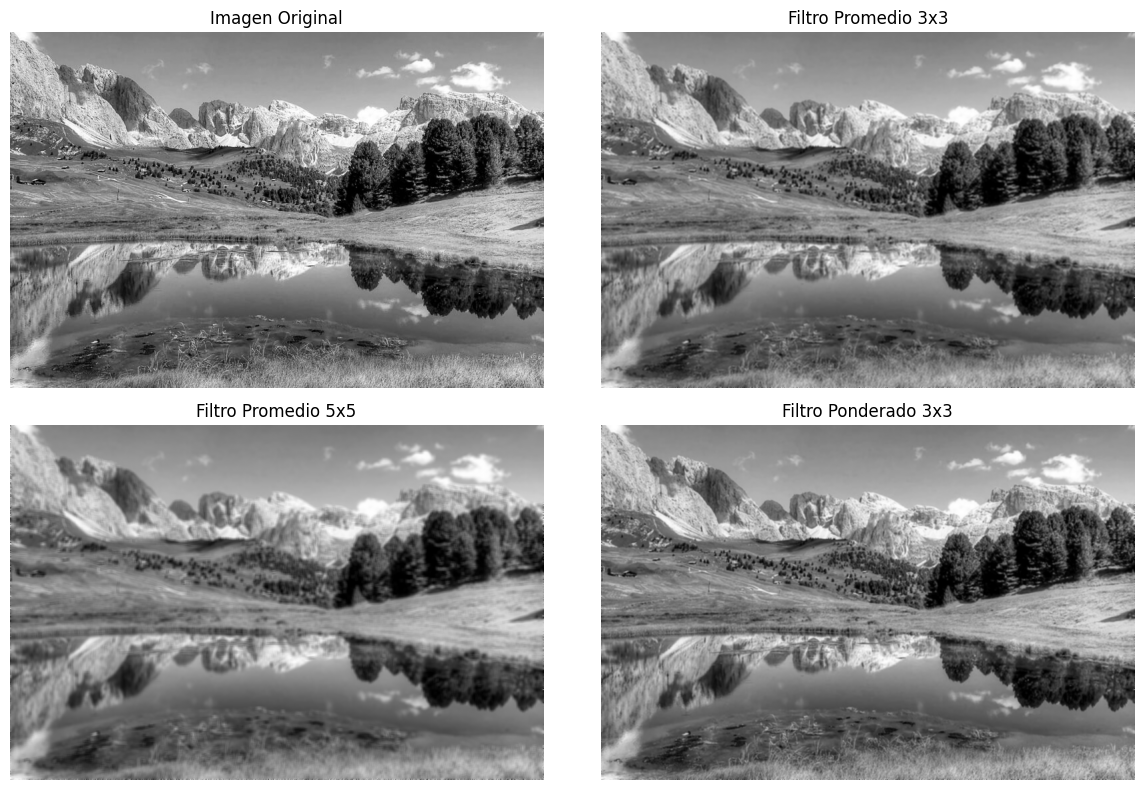

In [19]:
imagen = cv2.imread('images/paisaje.png', cv2.IMREAD_GRAYSCALE)

print("Tamaño de la imagen:", imagen.shape)

# Aplicar filtro promedio con mascara 1
imagen_filtrada1 = filtro_promedio(imagen, mascara1)
# Aplicar filtro promedio con mascara 2
imagen_filtrada2 = filtro_promedio(imagen, mascara2)
# Aplicar filtro promedio con mascara 3
imagen_filtrada3 = filtro_promedio(imagen, mascara3)

imagenes = [imagen, imagen_filtrada1, imagen_filtrada2, imagen_filtrada3]
titulos = ['Imagen Original', 'Filtro Promedio 3x3', 'Filtro Promedio 5x5', 'Filtro Ponderado 3x3']
# Mostrar imagen original y filtradas
fig, axs = plt.subplots(2,2, figsize=(12, 8))

for a, img, titulo in zip(axs.flat, imagenes, titulos):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(titulo)
    a.axis('off')

plt.tight_layout()
plt.savefig('results/resultado_filtro_promedio.png')
plt.show()



### Análisis de resultados — Punto 1

Se implementó una función de filtrado paso bajo utilizando ciclos for y se aplicaron tres máscaras sobre una imagen en escala de grises.

Al comparar los resultados, se observa que la máscara ponderada de 3×3 produce el menor suavizado y conserva mejor los detalles y bordes de las montañas, los árboles y sus reflejos en el agua.

Por otra parte, la máscara de promedio uniforme de 3×3 genera un suavizado mayor que la ponderada, haciendo que los bordes de los árboles y las montañas pierdan un poco más de definición. Finalmente, la máscara de 5×5 produce el desenfoque más evidente, con una mayor pérdida de detalles.

Estas diferencias se deben tanto al tamaño de la máscara como a la distribución de sus pesos. En la máscara ponderada, el píxel central tiene mayor importancia, por lo que se conservan mejor algunas características de la imagen original.

En conclusión, los filtros paso bajo reducen las variaciones de intensidad entre píxeles vecinos, produciendo un efecto de suavizado. Sin embargo, también pueden provocar una pérdida de detalles y definición de los bordes. En este caso, el filtro ponderado de 3×3 ofreció el mejor equilibrio entre suavizado y conservación de los detalles de la imagen.

## Punto2
Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la media (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

In [ ]:

def filtro_media(imagen, tamano):
    # Dimensiones imagen
    filas_imagen, columnas_imagen = imagen.shape

    #extension de la mascara
    extension = tamano // 2

    # Copia imagen original
    imagen_filtrada = imagen.astype(np.float64).copy()

    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension, filas_imagen - extension):